# Image reconstruction models: FCNN, autoencoder and U-Net

In [ ]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import torchvision.datasets as datasets
import torchvision.transforms as transforms


In [ ]:
!wget http://images.cocodataset.org/zips/train2017.zip
!wget http://images.cocodataset.org/zips/val2017.zip
!wget http://images.cocodataset.org/annotations/annotations_trainval2017.zip

--2025-09-22 13:56:46--  http://images.cocodataset.org/zips/train2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 3.5.24.132, 16.15.176.159, 3.5.23.162, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|3.5.24.132|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 19336861798 (18G) [application/zip]
Saving to: ‘train2017.zip’

train2017.zip       100%[===================>]  18.01G  39.7MB/s    in 6m 22s  

2025-09-22 14:03:09 (48.2 MB/s) - ‘train2017.zip’ saved [19336861798/19336861798]

--2025-09-22 14:03:09--  http://images.cocodataset.org/zips/val2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 3.5.27.31, 52.217.169.153, 3.5.28.125, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|3.5.27.31|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 815585330 (778M) [application/zip]
Saving to: ‘val2017.zip’

val2017.zip         100%[===================>] 777.80M  48.8MB/s  

In [ ]:
!mkdir -p ./data/coco
print("Done")
!unzip -q train2017.zip -d ./data/coco/
!unzip -q val2017.zip -d ./data/coco/
!unzip -q annotations_trainval2017.zip -d ./data/coco/

In [ ]:
def load_dataset(dataset_name, batch_size=64):
    if dataset_name == "mnist":
        transform = transforms.ToTensor()
        train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
        test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

    elif dataset_name == "cifar10":
        transform = transforms.Compose([
            transforms.ToTensor()
        ])
        train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
        test_dataset  = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

    elif dataset_name == "coco":
        transform = transforms.Compose([
            transforms.Resize((64, 64)),  # réduire la taille pour aller plus vite
            transforms.ToTensor()
        ])
        train_dataset = datasets.CocoDetection(
            root="./data/coco/train2017",
            annFile="./data/coco/annotations/instances_train2017.json",
            transform=transform
        )
        test_dataset = datasets.CocoDetection(
            root="./data/coco/val2017",
            annFile="./data/coco/annotations/instances_val2017.json",
            transform=transform
        )

        # Pour COCO on ne garde que les images (on ignore les annotations)
        train_dataset = [img for img, _ in train_dataset]
        test_dataset  = [img for img, _ in test_dataset]

    else:
        raise ValueError("Dataset non supporté")

    # Extraction des images en tenseurs
    if dataset_name != "coco":
        clean_train_imgs = torch.stack([img for img, _ in train_dataset])
        clean_test_imgs  = torch.stack([img for img, _ in test_dataset])
    else:
        clean_train_imgs = torch.stack(train_dataset)
        clean_test_imgs  = torch.stack(test_dataset)

    # Ajout du bruit
    noisy_train_imgs = add_noise(clean_train_imgs, std=0.3)
    noisy_train_imgs = add_salt_pepper_noise(noisy_train_imgs, prob=0.1)
    noisy_test_imgs = add_noise(clean_test_imgs, std=0.3)
    noisy_test_imgs = add_salt_pepper_noise(noisy_test_imgs, prob=0.1)

    # DataLoaders
    train_loader = DataLoader(TensorDataset(noisy_train_imgs, clean_train_imgs), batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(TensorDataset(noisy_test_imgs, clean_test_imgs), batch_size=batch_size, shuffle=False)

    return train_loader, test_loader

In [ ]:
# Affichage des images
def show_images(dataset_to_show, number_of_images):
    images = dataset_to_show.detach().cpu().numpy()
    fig, axes = plt.subplots(1, number_of_images, figsize=(12, 2))
    for i in range(number_of_images):
        axes[i].imshow(images[i], cmap="gray")
        axes[i].axis("off")
    plt.show()

In [ ]:
def show_images_comp(dataset_1, dataset_2, number_of_images):
    fig, axes = plt.subplots(number_of_images, 2, figsize=(4, number_of_images*2))
    for n, data in enumerate([dataset_1, dataset_2]):
        images = data.detach().cpu().numpy()
        for i in range(number_of_images):
            axes[i,n].imshow(images[i], cmap="gray")
            axes[i,n].axis("off")
    plt.show()

In [ ]:
def add_noise(t, std=0.3):
    noise = torch.randn(t.shape) * std
    noisy = torch.clamp(t + noise, 0., 1.)
    return noisy

In [ ]:
def add_salt_pepper_noise(images, prob=0.05):
    noisy = images.clone()
    rnd = torch.rand_like(noisy)
    noisy[rnd < prob/2] = 0.0
    noisy[rnd > 1 - prob/2] = 1.0
    return noisy

In [ ]:
class FCNN(nn.Module):
    def __init__(self, in_channels=1, img_size=28, hidden_size=500):
        super(FCNN, self).__init__()
        in_size = in_channels * img_size * img_size
        out_size = in_size
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, out_size), nn.Sigmoid()
        )
        self.in_channels = in_channels
        self.img_size = img_size

    def forward(self, x):
        x = self.model(x)
        return x.view(-1, self.in_channels, self.img_size, self.img_size)

In [ ]:
class FCAutoencoder(nn.Module):
    def __init__(self, in_channels=1, img_size=28, hidden1=512, hidden2=128, latent_size=32):
        super(FCAutoencoder, self).__init__()
        in_size = in_channels * img_size * img_size
        out_size = in_size

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_size, hidden1), nn.ReLU(),
            nn.Linear(hidden1, hidden2), nn.ReLU(),
            nn.Linear(hidden2, latent_size), nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden2), nn.ReLU(),
            nn.Linear(hidden2, hidden1), nn.ReLU(),
            nn.Linear(hidden1, out_size), nn.Sigmoid()
        )

        self.in_channels = in_channels
        self.img_size = img_size

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat.view(-1, self.in_channels, self.img_size, self.img_size)

In [ ]:
class UNet(nn.Module):
    def __init__(self, in_channels=1):
        super(UNet, self).__init__()

        # Encodeur
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1), nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU()
        )

        # Decodeur
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU()
        )

        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(32, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1), nn.ReLU()
        )

        # Sortie
        self.out_conv = nn.Conv2d(16, in_channels, kernel_size=1)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        b = self.bottleneck(p2)

        u2 = self.up2(b)
        u2 = torch.cat([u2, e2], dim=1)
        d2 = self.dec2(u2)

        u1 = self.up1(d2)
        u1 = torch.cat([u1, e1], dim=1)
        d1 = self.dec1(u1)

        out = self.out_conv(d1)
        return self.activation(out)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def init_model(model_class):
    return model_class().to(device)

Using device: cuda


In [ ]:
criterion = nn.MSELoss()

def train_model(model, optimizer, train_loader, test_loader, num_epochs=10):
    train_losses, test_losses = [], []
    for epoch in range(num_epochs):
        model.train()
        running_train = 0.0
        for noisy, clean in train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            outputs = model(noisy)
            loss = criterion(outputs, clean)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_train += loss.item() * noisy.size(0)
        epoch_train_loss = running_train / len(train_loader.dataset)

        model.eval()
        running_test = 0.0
        with torch.no_grad():
            for noisy, clean in test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                outputs = model(noisy)
                loss = criterion(outputs, clean)
                running_test += loss.item() * noisy.size(0)
        epoch_test_loss = running_test / len(test_loader.dataset)

        train_losses.append(epoch_train_loss)
        test_losses.append(epoch_test_loss)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train: {epoch_train_loss:.6f} | Test: {epoch_test_loss:.6f}")

    return train_losses, test_losses


In [ ]:
def show_reconstructions(model, loader, n=6):
    model.eval()
    noisy, clean = next(iter(loader))
    noisy = noisy.to(device)
    with torch.no_grad():
        outputs = model(noisy)
    noisy, clean, outputs = noisy.cpu(), clean.cpu(), outputs.cpu()

    fig, axes = plt.subplots(3, n, figsize=(12, 5))
    for i in range(n):
        axes[0, i].imshow(noisy[i][0], cmap="gray"); axes[0, i].axis("off")
        if i == 0: axes[0, i].set_title("Noisy")
        axes[1, i].imshow(outputs[i][0], cmap="gray"); axes[1, i].axis("off")
        if i == 0: axes[1, i].set_title("Denoised")
        axes[2, i].imshow(clean[i][0], cmap="gray"); axes[2, i].axis("off")
        if i == 0: axes[2, i].set_title("Clean")
    plt.show()


In [ ]:
import math
!pip install torchmetrics
from torchmetrics.functional import structural_similarity_index_measure as ssim


In [ ]:
def psnr(mse, max_val=1.0):
    if mse == 0:
        return 100
    return 10 * math.log10(max_val**2 / mse)

In [ ]:
def evaluate_model(model, loader):
    model.eval()
    mse_total, psnr_total, ssim_total = 0, 0, 0
    count = 0
    with torch.no_grad():
        for noisy, clean in loader:
            noisy, clean = noisy.to(device), clean.to(device)
            outputs = model(noisy)

            mse_batch = nn.functional.mse_loss(outputs, clean, reduction="mean").item()
            mse_total += mse_batch
            psnr_total += psnr(mse_batch, max_val=1.0)
            ssim_total += ssim(outputs, clean, data_range=1.0).item()

            count += 1
    return (mse_total/count, psnr_total/count, ssim_total/count)



=== Dataset: MNIST ===

===== Training FCNN on mnist =====
Epoch [1/10] Train: 0.035061 | Test: 0.020621
Epoch [2/10] Train: 0.017828 | Test: 0.015555
Epoch [3/10] Train: 0.014453 | Test: 0.013705
Epoch [4/10] Train: 0.012760 | Test: 0.012659
Epoch [5/10] Train: 0.011742 | Test: 0.012368
Epoch [6/10] Train: 0.011046 | Test: 0.011655
Epoch [7/10] Train: 0.010505 | Test: 0.011518
Epoch [8/10] Train: 0.010088 | Test: 0.011293
Epoch [9/10] Train: 0.009767 | Test: 0.011439
Epoch [10/10] Train: 0.009453 | Test: 0.011078


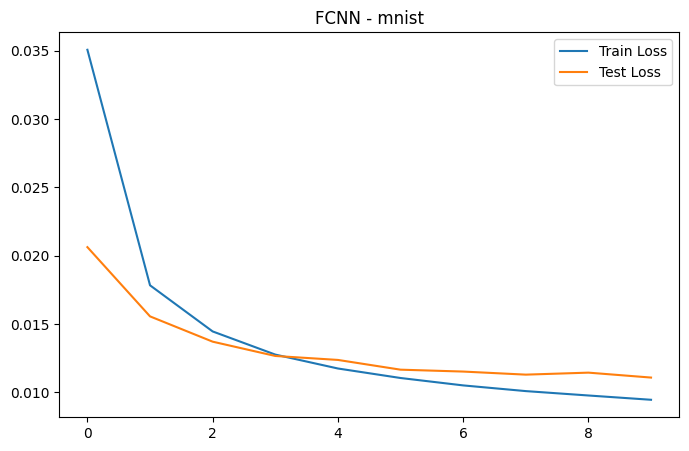

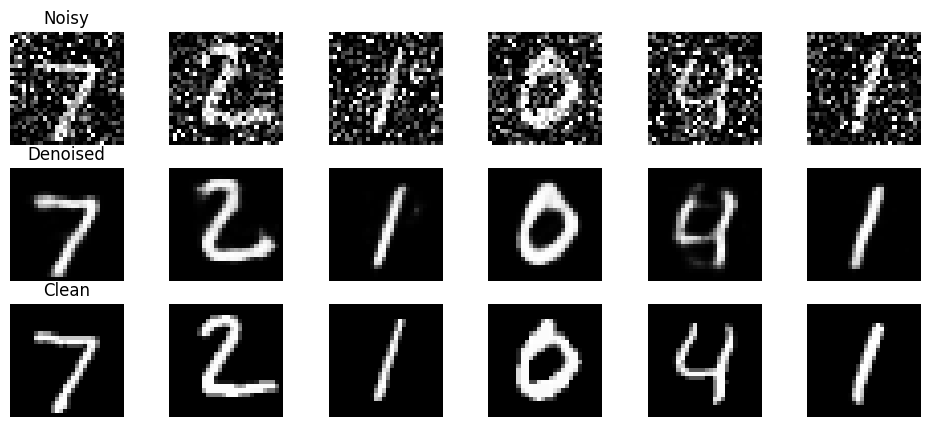


===== Training FCAutoencoder on mnist =====
Epoch [1/10] Train: 0.045341 | Test: 0.029193
Epoch [2/10] Train: 0.025950 | Test: 0.022773
Epoch [3/10] Train: 0.021072 | Test: 0.019345
Epoch [4/10] Train: 0.018325 | Test: 0.017974
Epoch [5/10] Train: 0.016870 | Test: 0.016689
Epoch [6/10] Train: 0.015910 | Test: 0.016385
Epoch [7/10] Train: 0.015222 | Test: 0.015869
Epoch [8/10] Train: 0.014636 | Test: 0.015427
Epoch [9/10] Train: 0.014155 | Test: 0.015403
Epoch [10/10] Train: 0.013762 | Test: 0.015389


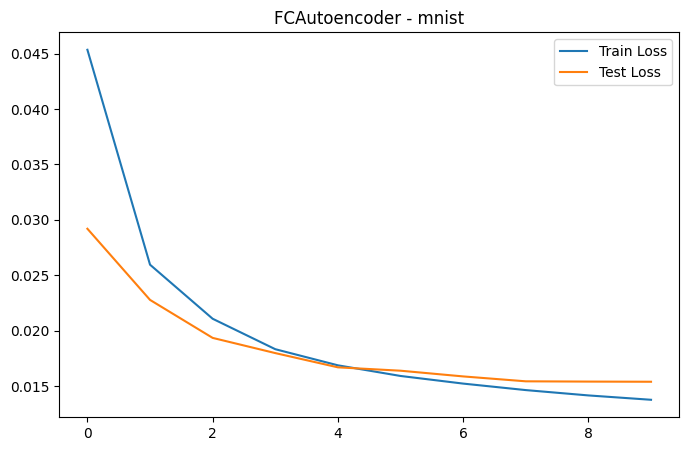

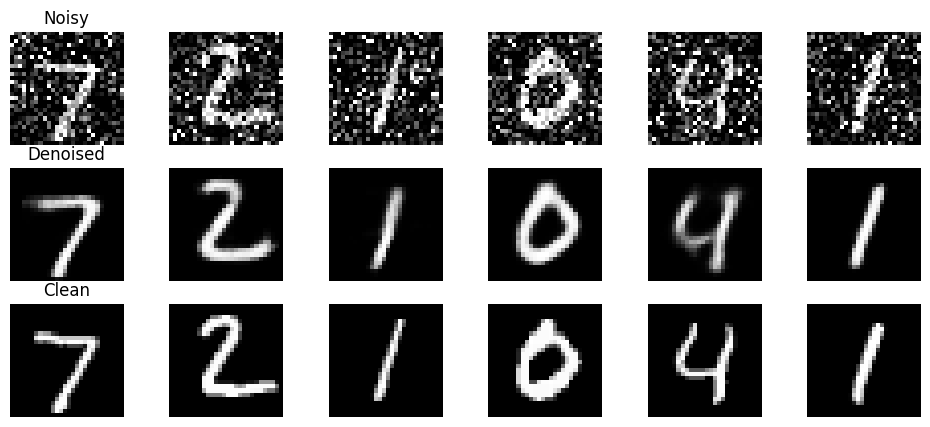


===== Training UNet on mnist =====
Epoch [1/10] Train: 0.113210 | Test: 0.113958
Epoch [2/10] Train: 0.112003 | Test: 0.113958
Epoch [3/10] Train: 0.112003 | Test: 0.113958
Epoch [4/10] Train: 0.112003 | Test: 0.113958
Epoch [5/10] Train: 0.112003 | Test: 0.113958
Epoch [6/10] Train: 0.112003 | Test: 0.113958
Epoch [7/10] Train: 0.112003 | Test: 0.113958
Epoch [8/10] Train: 0.112003 | Test: 0.113958
Epoch [9/10] Train: 0.112003 | Test: 0.113958
Epoch [10/10] Train: 0.112003 | Test: 0.113958


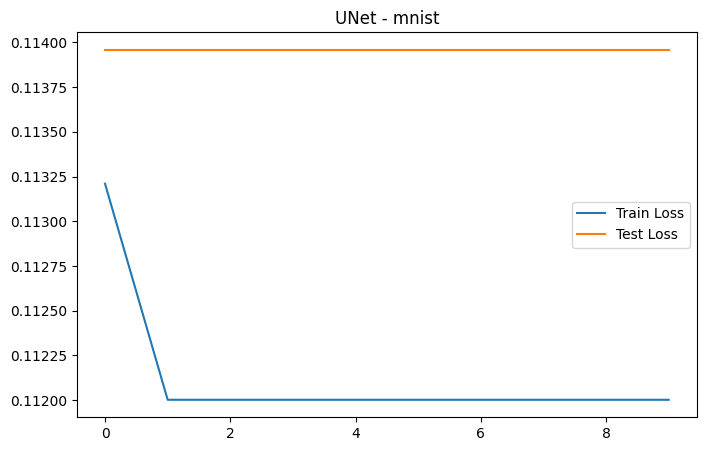

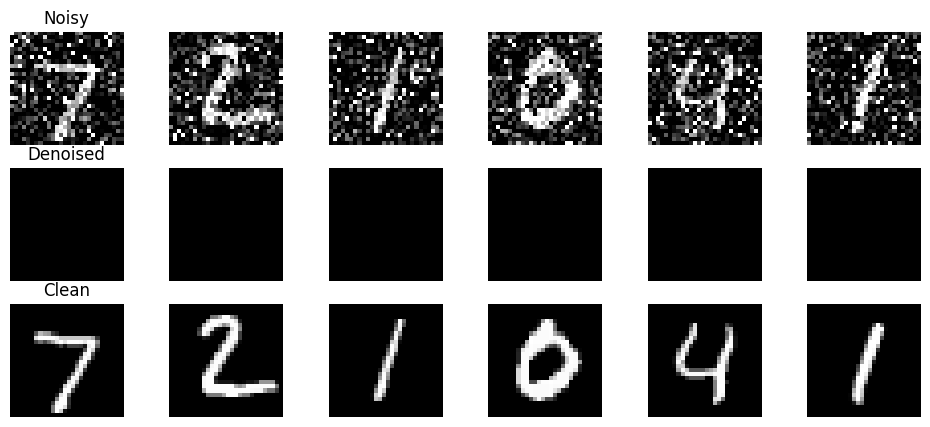



=== Dataset: CIFAR10 ===

===== Training FCNN on cifar10 =====
Epoch [1/10] Train: 0.030409 | Test: 0.024981
Epoch [2/10] Train: 0.021173 | Test: 0.019349
Epoch [3/10] Train: 0.018114 | Test: 0.017637
Epoch [4/10] Train: 0.016816 | Test: 0.016509
Epoch [5/10] Train: 0.015942 | Test: 0.016057
Epoch [6/10] Train: 0.015158 | Test: 0.015073
Epoch [7/10] Train: 0.014705 | Test: 0.015334
Epoch [8/10] Train: 0.014435 | Test: 0.014616
Epoch [9/10] Train: 0.014085 | Test: 0.014529
Epoch [10/10] Train: 0.013775 | Test: 0.014191


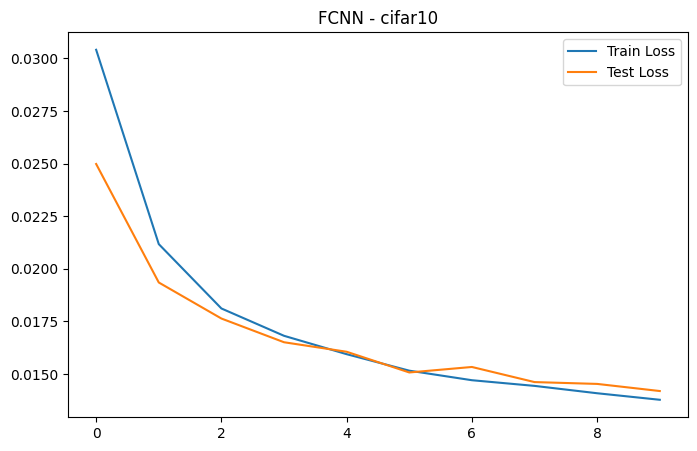

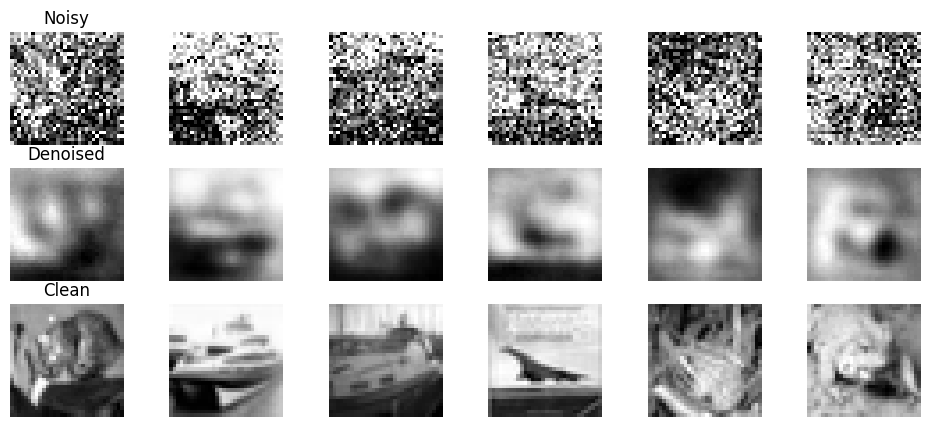


===== Training FCAutoencoder on cifar10 =====
Epoch [1/10] Train: 0.030549 | Test: 0.025055
Epoch [2/10] Train: 0.023635 | Test: 0.022521
Epoch [3/10] Train: 0.021800 | Test: 0.021670
Epoch [4/10] Train: 0.020854 | Test: 0.020534
Epoch [5/10] Train: 0.020044 | Test: 0.020020
Epoch [6/10] Train: 0.019462 | Test: 0.019368
Epoch [7/10] Train: 0.018804 | Test: 0.019066
Epoch [8/10] Train: 0.018612 | Test: 0.019005
Epoch [9/10] Train: 0.018498 | Test: 0.018890
Epoch [10/10] Train: 0.018364 | Test: 0.018974


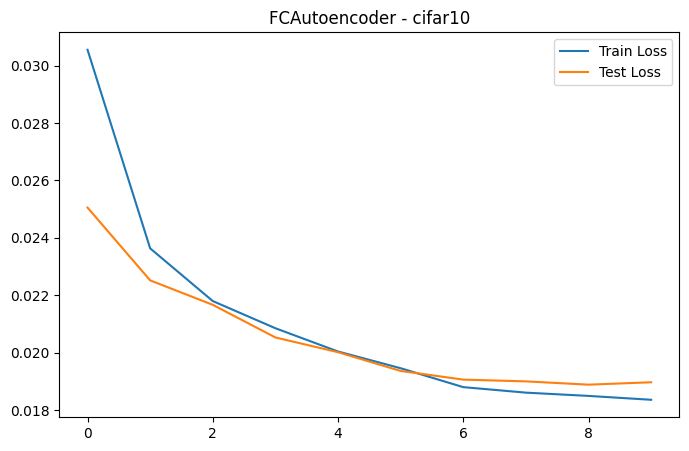

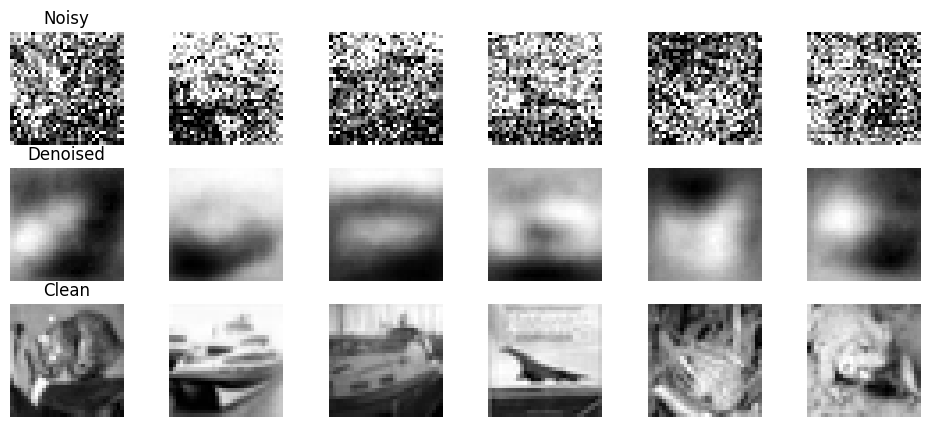


===== Training UNet on cifar10 =====
Epoch [1/10] Train: 0.013323 | Test: 0.009404
Epoch [2/10] Train: 0.008661 | Test: 0.008179
Epoch [3/10] Train: 0.007978 | Test: 0.007768
Epoch [4/10] Train: 0.007710 | Test: 0.007550
Epoch [5/10] Train: 0.007558 | Test: 0.007544
Epoch [6/10] Train: 0.007436 | Test: 0.007412
Epoch [7/10] Train: 0.007335 | Test: 0.007339
Epoch [8/10] Train: 0.007249 | Test: 0.007284
Epoch [9/10] Train: 0.007184 | Test: 0.007284
Epoch [10/10] Train: 0.007130 | Test: 0.007098


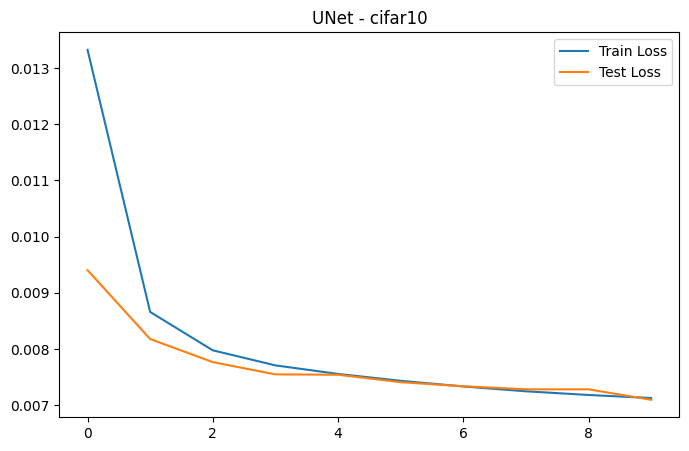

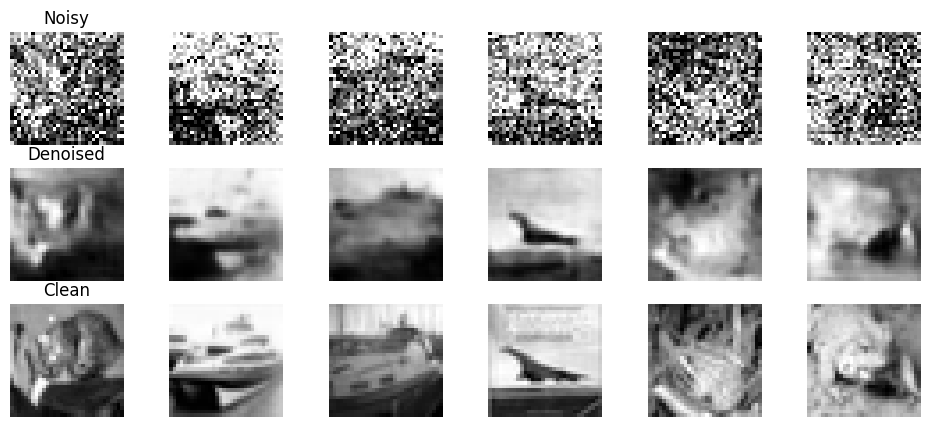



=== Dataset: COCO ===
loading annotations into memory...
Done (t=12.85s)
creating index...
index created!
loading annotations into memory...
Done (t=0.52s)
creating index...
index created!


In [ ]:
models = {
    "FCNN": FCNN,
    "FCAutoencoder": FCAutoencoder,
    "UNet": UNet
}

datasets_list = ["mnist", "cifar10","coco"]
results = {}

for dataset_name in datasets_list:
    print(f"\n\n=== Dataset: {dataset_name.upper()} ===")
    train_loader, test_loader = load_dataset(dataset_name)

    # Définir les paramètres d'entrée
    if dataset_name == "mnist":
        in_channels, img_size = 1, 28
    elif dataset_name == "cifar10":
        in_channels, img_size = 3, 32
    elif dataset_name == "coco":
        in_channels, img_size = 3, 64

    dataset_results = {}

    for name, model_class in models.items():
        print(f"\n===== Training {name} on {dataset_name} =====")
        if name == "UNet":
          model = model_class(in_channels=in_channels).to(device)
        else:
          model = model_class(in_channels=in_channels, img_size=img_size).to(device)

        optimizer = optim.Adam(model.parameters(), lr=1e-3)

        train_losses, test_losses = train_model(model, optimizer, train_loader, test_loader, num_epochs=10)

        mse_val, psnr_val, ssim_val = evaluate_model(model, test_loader)
        dataset_results[name] = (mse_val, psnr_val, ssim_val)

        # Courbes
        plt.figure(figsize=(8,5))
        plt.plot(train_losses, label="Train Loss")
        plt.plot(test_losses, label="Test Loss")
        plt.title(f"{name} - {dataset_name}")
        plt.legend()
        plt.show()

        # Reconstructions
        show_reconstructions(model, test_loader)

    results[dataset_name] = dataset_results


In [ ]:
import pandas as pd

for dataset_name, res in results.items():
    print(f"\n=== Résultats sur {dataset_name.upper()} ===")
    df_results = pd.DataFrame.from_dict(
        res, orient="index", columns=["MSE", "PSNR (dB)", "SSIM"]
    )
    display(df_results)
